# EDA

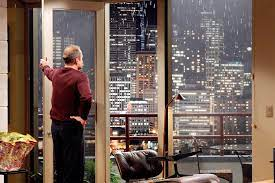

## 1. Projektstart

### Stakeholder
Zachary Brooks (Verkäufer): Investiert in historische Häuser in den besten Lagen von King County. Er will hohe Profite, den besten Verkaufszeitpunkt innerhalb eines Jahres und wissen, ob sich eine Renovierung lohnt.

### Geschäftsziel / Fragestellung
Wie kann Zachary Brooks mit historischen Häusern in Top-Lagen seinen Gewinn maximieren, und welche Rolle spielen dabei Renovierung und Verkaufszeitpunkt?

### Hypothesen

| | Hypothese | Relevante Spalten |
|---|---|---|
| **H1** | Historische Häuser erzielen in Top-Lagen einen höheren Preis pro sqft als neuere Häuser in denselben Zipcodes. | `yr_built`, `price`, `sqft_living`, `zipcode` |
| **H2** | Renovierte Häuser erzielen höhere Verkaufspreise als vergleichbare nicht renovierte Häuser. Der Effekt ist bei historischen Häusern besonders stark. | `yr_renovated`, `condition`, `grade`, `price` |
| **H3** | Verkäufe zwischen März und August erzielen höhere Preise (Median-Preis bzw. Preis pro sqft) als Verkäufe zwischen September und Februar. | `date`, `price` |

### Annahmen
- **Historisch:** Baujahr vor 1950 (Vorkriegs- und frühe Nachkriegszeit). Die Grenze wird auf Robustheit mit 1930, 1940 und 1960 verglichen.
- **Top-Lage:** Zipcodes, deren Median-Verkaufspreis im obersten Dezil (obere 10 %) aller Zipcodes liegt.
- **Renovierung:** `yr_renovated > 0` gilt als renoviert, `0` als nicht renoviert. Fehlende Werte (`NaN`) gelten als unbekannt und werden bei H2 nicht berücksichtigt.
- **Profit:** Der Datensatz enthält nur Verkaufspreise, keine Einkaufs- oder Renovierungskosten. Als Näherung dienen Preis und Preis pro sqft.
- **Mehrfachverkäufe:** 177 Häuser wurden im Zeitraum zweimal verkauft. Jeder Verkauf zählt als eigener Datenpunkt.
- **Hochsaison:** März bis August, alle anderen Monate gelten als Nebensaison.

### Limitationen
- Der Datensatz deckt nur ca. ein Jahr ab (02.05.2014 bis 27.05.2015). Saisonalität lässt sich daher nicht von einem allgemeinen Preistrend trennen.
- Die Hochsaison-Gruppe stammt aus zwei verschiedenen Jahren (Mai bis August 2014 und März bis Mai 2015).
- Bei `yr_renovated` fehlen rund 18 % der Werte, und die Zahl renovierter Häuser ist vergleichsweise klein.

In [64]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

## 2. Daten laden und erster Überblick 

In [65]:
df = pd.read_csv("data/king_county_joined.csv")
print(df.shape)
df.head()

(21597, 22)


,sale_id,house_id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,1,7129300520,2014-10-13,221900.000,3.000,1.000,1180.000,5650.000,1.000,NaN,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,2,6414100192,2014-12-09,538000.000,3.000,2.250,2570.000,7242.000,2.000,0.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,3,5631500400,2015-02-25,180000.000,2.000,1.000,770.000,10000.000,1.000,0.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,4,2487200875,2014-12-09,604000.000,4.000,3.000,1960.000,5000.000,1.000,0.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,5,1954400510,2015-02-18,510000.000,3.000,2.000,1680.000,8080.000,1.000,0.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sale_id        21597 non-null  int64  
 1   house_id       21597 non-null  int64  
 2   date           21597 non-null  str    
 3   price          21597 non-null  float64
 4   bedrooms       21597 non-null  float64
 5   bathrooms      21597 non-null  float64
 6   sqft_living    21597 non-null  float64
 7   sqft_lot       21597 non-null  float64
 8   floors         21597 non-null  float64
 9   waterfront     19206 non-null  float64
 10  view           21534 non-null  float64
 11  condition      21597 non-null  int64  
 12  grade          21597 non-null  int64  
 13  sqft_above     21597 non-null  float64
 14  sqft_basement  21145 non-null  float64
 15  yr_built       21597 non-null  int64  
 16  yr_renovated   17749 non-null  float64
 17  zipcode        21597 non-null  int64  
 18  lat            21

In [67]:
df.isna().sum()

sale_id             0
house_id            0
date                0
price               0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       2391
view               63
condition           0
grade               0
sqft_above          0
sqft_basement     452
yr_built            0
yr_renovated     3848
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
dtype: int64

## 3. Data Cleaning

In [68]:
# Wandelt den Text in der Spalte "date" in ein echtes Datum um
df["date"] = pd.to_datetime(df["date"])

In [69]:
# Zählt Zeilen, die komplett doppelt vorkommen
df.duplicated().sum()

np.int64(0)

In [70]:
# Zählt Häuser (house_id), die mehr als einmal verkauft wurden
df["house_id"].duplicated().sum()

np.int64(177)

In [71]:
# Zeigt, wie oft jeder Wert vorkommt (inkl. NaN), nur die häufigsten 10
df["yr_renovated"].value_counts(dropna=False).head(10)

yr_renovated
0.000        17005
NaN           3848
20140.000       73
20130.000       31
20030.000       31
20070.000       30
20050.000       29
20000.000       29
19900.000       22
20040.000       22
Name: count, dtype: int64

In [72]:
# Teilt alle Werte größer 0 durch 10, damit aus 20140.0 das Jahr 2014 wird (NaN und 0 bleiben unverändert)
df["yr_renovated"] = df["yr_renovated"].where(df["yr_renovated"].isna() | (df["yr_renovated"] == 0), df["yr_renovated"] / 10)

In [73]:
# Prüft, ob jetzt realistische Jahre (z. B. 1934 bis 2015) herauskommen
df["yr_renovated"].replace(0, pd.NA).dropna().agg(["min", "max"])

min   1934.000
max   2015.000
Name: yr_renovated, dtype: float64

In [74]:
# Erstellt eine Hilfsspalte: "ja" wenn Renovierungsjahr > 0, "nein" wenn 0, sonst unbekannt (NaN) weil zu viele Daten zum löschen.
df["renovated"] = df["yr_renovated"].apply(lambda x: pd.NA if pd.isna(x) else (x > 0))

In [75]:
# Zählt, wie viele Häuser renoviert, nicht renoviert oder unbekannt sind
df["renovated"].value_counts(dropna=False)

renovated
False    17005
<NA>      3848
True       744
Name: count, dtype: int64

In [76]:
# Frühestes und spätestes Verkaufsdatum im Datensatz
df["date"].min(), df["date"].max()

(Timestamp('2014-05-02 00:00:00'), Timestamp('2015-05-27 00:00:00'))

## 4. Feature Engineering und Annahmen

In [77]:
# Preis pro Quadratfuß Wohnfläche (für H1 und H3)
df["price_per_sqft"] = df["price"] / df["sqft_living"]

In [78]:
# Verkaufsmonat als Zahl 1 bis 12 (für H3)
df["month"] = df["date"].dt.month

In [79]:
# Markiert Verkäufe von März bis August als "Hochsaison", alle anderen als "Nebensaison" (für H3)
df["season"] = df["month"].apply(lambda m: "Hochsaison" if 3 <= m <= 8 else "Nebensaison")

In [80]:
# Markiert historische Häuser (Baujahr vor 1940) für H1
df["historic"] = df["yr_built"] < 1940

In [81]:
# Zählt renovierte und nicht renovierte Häuser getrennt für historische (True) und neuere (False) Häuser (vorher die Spalte "historic" aus dem letzten Schritt anlegen)
df["historic"] = df["yr_built"] < 1940
df.groupby("historic")["renovated"].value_counts()

historic  renovated
False     False        14757
          True           398
True      False         2248
          True           346
Name: count, dtype: int64

In [82]:
# Zählt Häuser pro Altersgrenze (vor 1930, 1940, 1950, 1960), um die Stichprobengröße zu vergleichen
for grenze in [1930, 1940, 1950, 1960]:
    print(grenze, (df["yr_built"] < grenze).sum())

1930 2642
1940 3172
1950 4935
1960 7385


In [83]:
# Zählt renovierte Häuser pro Altersgrenze (nur True), um die Stichprobe für H2 zu sehen
for grenze in [1930, 1940, 1950, 1960]:
    print(grenze, ((df["yr_built"] < grenze) & (df["renovated"] == True)).sum())

1930 274
1940 346
1950 470
1960 600


### 4.1 Top-Zipcodes
**Annahme:** Top-Lage = Zipcodes, deren Median-Verkaufspreis im obersten Dezil aller Zipcodes liegt.

In [84]:
# Median-Verkaufspreis pro Zipcode berechnen
zip_median = df.groupby("zipcode")["price"].median()

In [85]:
# Schwellenwert: das 90%-Quantil der Zipcode-Mediane (alles darüber = Top 10 %)
threshold = zip_median.quantile(0.9)

In [86]:
# Liste der Top-Zipcodes (Median-Preis liegt auf oder über dem Schwellenwert)
top_zips = zip_median[zip_median >= threshold].index
print(len(top_zips), sorted(top_zips))

7 [98004, 98005, 98006, 98039, 98040, 98112, 98119]


In [87]:
# Neue Spalte: True, wenn das Haus in einem Top-Zipcode liegt
df["top_zip"] = df["zipcode"].isin(top_zips)

In [88]:
# Zählt, wie viele Verkäufe in Top-Zipcodes liegen
df["top_zip"].value_counts()

top_zip
False    19829
True      1768
Name: count, dtype: int64

**Ergebnis:** 7 von rund 70 Zipcodes zählen als Top-Lage (98004, 98005, 98006, 98039, 98040, 98112, 98119). 
Sie enthalten 1.768 Verkäufe (ca. 8 % aller Verkäufe).

### 4.2 Historische Häuser und Stichprobengröße
**Annahme:** Historisch = Baujahr vor 1950. 

In [89]:
# Zählt Häuser nach Kombination: Top-Zipcode, historisch (<1950) und renoviert-Status
df["historic"] = df["yr_built"] < 1950
df[df["top_zip"]].groupby("historic")["renovated"].value_counts(dropna=False)

historic  renovated
False     False        1112
          NaN           245
          True           62
True      False         232
          True           62
          NaN            55
Name: count, dtype: int64

**Ergebnis:** In Top-Zipcodes gibt es 349 historische Häuser (davon 62 renoviert, 232 nicht renoviert, 55 unbekannt). Für H1 ist die Stichprobe ausreichend. 
Für H2 ist sie bei historischen Häusern klein, daher wird H2 zusätzlich über alle Top-Zipcode-Häuser geprüft.